<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV2__Line%C3%A1rn%C3%AD_regrese.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 2. -  Lineární regrese
---
V tomto cvičení probereme základy **lineární regrese**, k čemu je dobrá a jak ji prakticky používat. Také si ukážeme jak správně načíst, prozkoumat a případně vyčistit **dataset**.

**1. Myšlenka**

Než poskládáme jakýkoliv model, musíme se prvně zamyslet: Co vlastně chceme modelovat? Co chceme předpovídat?

*Příklad:* Chci předpovídat medián ceny domů (`median_house_value`) v dané oblasti (`longitude`, `latitude`).

**2. Data**

Ve chvíli kdy máme myšlenku tak jsou na řadě data. Je nutné si z vybraných dat vybrat ta data, která budou nejvhodnější k tomu aby model správně fungoval. K tomu použijeme výsledky naší explorační analýzy.

*Příklad:* Dle heatmapy by k tomu mohl být užitečný parametr `median_income`. Naopak, např. parametr `longditude`, `latidute` nebo `housing_media_age` nebude příliš vhodný. Jedná e ovšem o čistě lineární vztahy, takže nám mohou zůstat některé závislosti skryté.

**3. Model**
Když máme myšlenku, data tak je nařadě vybrat vhodný model. To se dělá v závislosti na datech - podle toho zda jsou to jsou časové řady, obrázky, text, numerické hodnoty... A také zda jsou lineární či periodické, nebo naopak nemají žádný viditelný vzor a jsou to křivky atd.

**Příklad:** V tomto případě by mohl stačit obyčejný **lineární model**, protože  heatmapa hledá lineární vztahy a ty jsou v tomto případě silné, alespoň v případěc `median_income`.

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Knihovna pro práci s lin. regresí
from sklearn.linear_model import LinearRegression

## 📃 ČÁST 1: Práce s datasety
---
Zde si ukážeme jak efektivně a jednoduše načíst dataset, jak nad ním provést jednoduchou explorační analýzu a případně jej vyčistit od nevalidních či nehodících se dat.

Existují 3 základní zdroje datasetu:
- **lokální soubor** : dataset je uložen v místím uložišti jako soubor, např. CSV, XML, JSON...
- **link** : dataset je načten přes internet, stačí nám odkaz na něj (link na online  [datasety Kaggle.com](https://www.kaggle.com/datasets) a [Google Datasets](https://datasetsearch.research.google.com/))
- **knihovna** : dataset je již součástí nějaké knihovny, například *Keras*

In [ ]:
# Načtení lokálního CSV souboru a převod na DataFrame
"""
Jméno souboru je california_housing_train.csv a nachází se v defaultní složce sample_file,
kterou nám Colab automaticky vytvoří pro testování
"""
df = pd.read_csv("sample_data/california_housing_train.csv")
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
...,...,...,...,...,...,...,...,...,...
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0


In [ ]:
# Načtení souboru pomocí linku a převod na DataFrame
df_link = pd.read_csv("https://raw.githubusercontent.com/nytimes/covid-19-data/master/us-counties-2020.csv")
df_link

,date,county,state,fips,cases,deaths
0,2020-01-21,Snohomish,Washington,53061.0,1,0.0
1,2020-01-22,Snohomish,Washington,53061.0,1,0.0
2,2020-01-23,Snohomish,Washington,53061.0,1,0.0
3,2020-01-24,Cook,Illinois,17031.0,1,0.0
4,2020-01-24,Snohomish,Washington,53061.0,1,0.0
...,...,...,...,...,...,...
884732,2020-12-31,Sweetwater,Wyoming,56037.0,2966,16.0
884733,2020-12-31,Teton,Wyoming,56039.0,2138,4.0
884734,2020-12-31,Uinta,Wyoming,56041.0,1558,7.0
884735,2020-12-31,Washakie,Wyoming,56043.0,780,19.0


In [ ]:
# Načtení datasetu z knihovny - zde dochází načtení dat v raw formátu (numpy array) a data jsou již předrozdělena na trénovací a testovací
# Tento formát je vhodný k trénování modelů strojového učení
import tensorflow.keras.datasets as datasets
(train_data, train_targets), (test_data, test_targets) = datasets.boston_housing.load_data()

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


In [ ]:
train_data.shape, test_data.shape

((404, 13), (102, 13))

In [ ]:
train_data[:5]

array([[1.23247e+00, 0.00000e+00, 8.14000e+00, 0.00000e+00, 5.38000e-01,
        6.14200e+00, 9.17000e+01, 3.97690e+00, 4.00000e+00, 3.07000e+02,
        2.10000e+01, 3.96900e+02, 1.87200e+01],
       [2.17700e-02, 8.25000e+01, 2.03000e+00, 0.00000e+00, 4.15000e-01,
        7.61000e+00, 1.57000e+01, 6.27000e+00, 2.00000e+00, 3.48000e+02,
        1.47000e+01, 3.95380e+02, 3.11000e+00],
       [4.89822e+00, 0.00000e+00, 1.81000e+01, 0.00000e+00, 6.31000e-01,
        4.97000e+00, 1.00000e+02, 1.33250e+00, 2.40000e+01, 6.66000e+02,
        2.02000e+01, 3.75520e+02, 3.26000e+00],
       [3.96100e-02, 0.00000e+00, 5.19000e+00, 0.00000e+00, 5.15000e-01,
        6.03700e+00, 3.45000e+01, 5.98530e+00, 5.00000e+00, 2.24000e+02,
        2.02000e+01, 3.96900e+02, 8.01000e+00],
       [3.69311e+00, 0.00000e+00, 1.81000e+01, 0.00000e+00, 7.13000e-01,
        6.37600e+00, 8.84000e+01, 2.56710e+00, 2.40000e+01, 6.66000e+02,
        2.02000e+01, 3.91430e+02, 1.46500e+01]])

## 🏡 California Housing Dataset

### Popis datasetu



In [ ]:
"""
Zdroj  souboru je california_housing_train.csv a nachází se v defaultní složce sample_file,
kterou nám Colab automaticky vytvoří pro testování
"""
df = pd.read_csv("sample_data/california_housing_train.csv")
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
...,...,...,...,...,...,...,...,...,...
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0


### 📘 Explorační analýza:
*Exploratory Data Analysis (EDA)* nám pomáhá pochopit povahu dat, najít charakteristiky dat, identifikovat vzory v datech a vytvářet vizuální a textové náhledy. 🖼 Případně odtranit nevalidní a odhlehlá data... ❌

In [ ]:
# Zobraz prvních pár řádků datasetu
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [ ]:
# Základní statistika
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
# Kontrola chybějících hodnot (null, NA)
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


In [ ]:
# Odstraň záznamy s chybějící hodnotou
df.dropna(inplace=True)

In [ ]:
# Datové typy sloupců
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
dtype: object

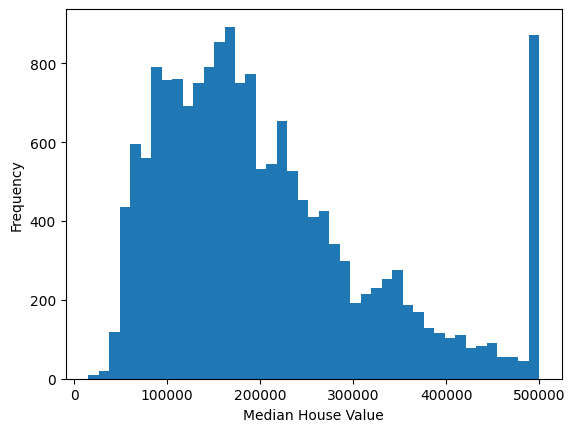

In [ ]:
# Histogram - median_house_value
plt.hist(df['median_house_value'], bins="auto", histtype="bar")
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

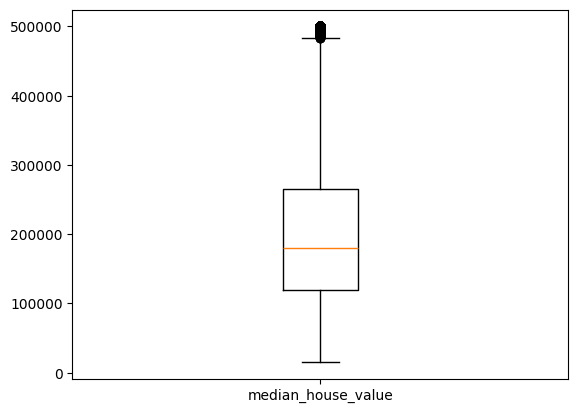

In [ ]:
# Boxplot - median_house_value
plt.boxplot(df['median_house_value'], tick_labels=["median_house_value"])
plt.show()

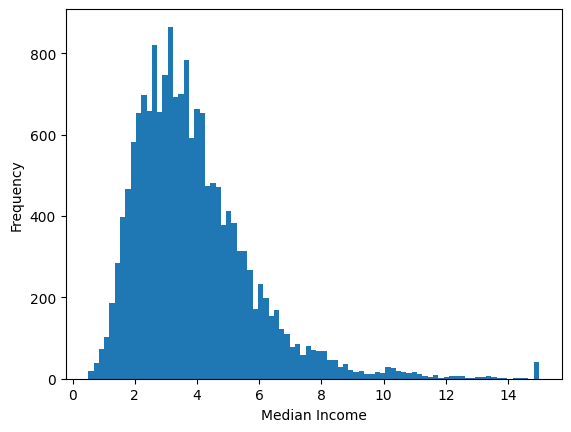

In [ ]:
plt.hist(df['median_income'], bins="auto", histtype="bar")
plt.xlabel('Median Income')
plt.ylabel('Frequency')
plt.show()

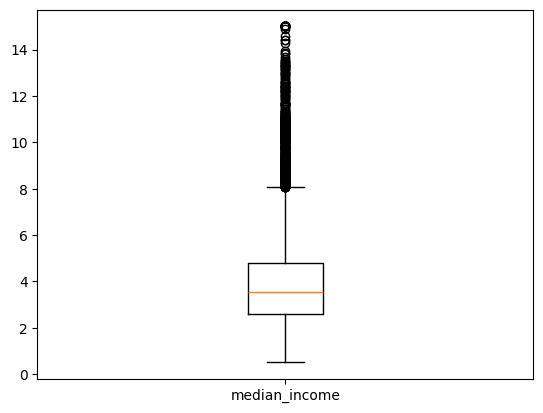

In [ ]:
plt.boxplot(df['median_income'], tick_labels=["median_income"])
plt.show()

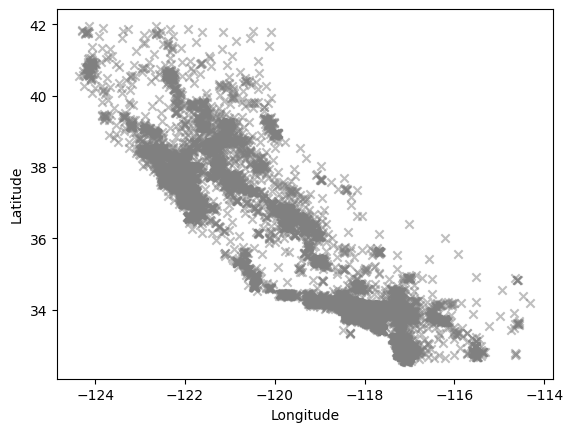

In [ ]:
# Vykreslení bodů longitude a latitude jako scatter plot s X body
plt.scatter(df['longitude'], df['latitude'], alpha=0.5, marker="x", color="gray")
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

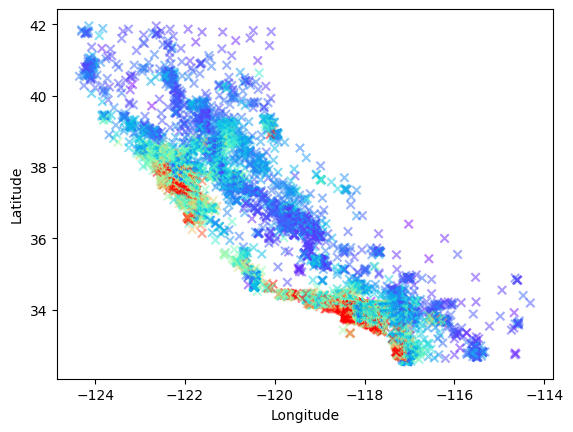

In [ ]:
# Vykreslení polohy domů včetně cenové úrovně
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

cmap_norm = Normalize(vmin=df["median_house_value"].min(), vmax=df["median_house_value"].max(), clip=True)
colors = plt.cm.rainbow(cmap_norm(df["median_house_value"]))

plt.scatter(df['longitude'], df['latitude'], alpha=0.5, marker="x", c=colors)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

🧠 **Co** by nás mohlo dále zajímat? Jaké grafy?

**Korelační mapa 🗺**

Tato mapa nám **pomáhá hledat závislosti v datech** - které **featury jsou na sobě závislé**. Jsou to tzv. závislé proměnné. Existuje několik možných korelačních metod, většina má ale společný **rozsah hodnot od 1 do -1**, kde hodnoty okolo +-1 značí silnou korelaci, a hodnoty okolo 0 značí žádnou či velmi slabou.

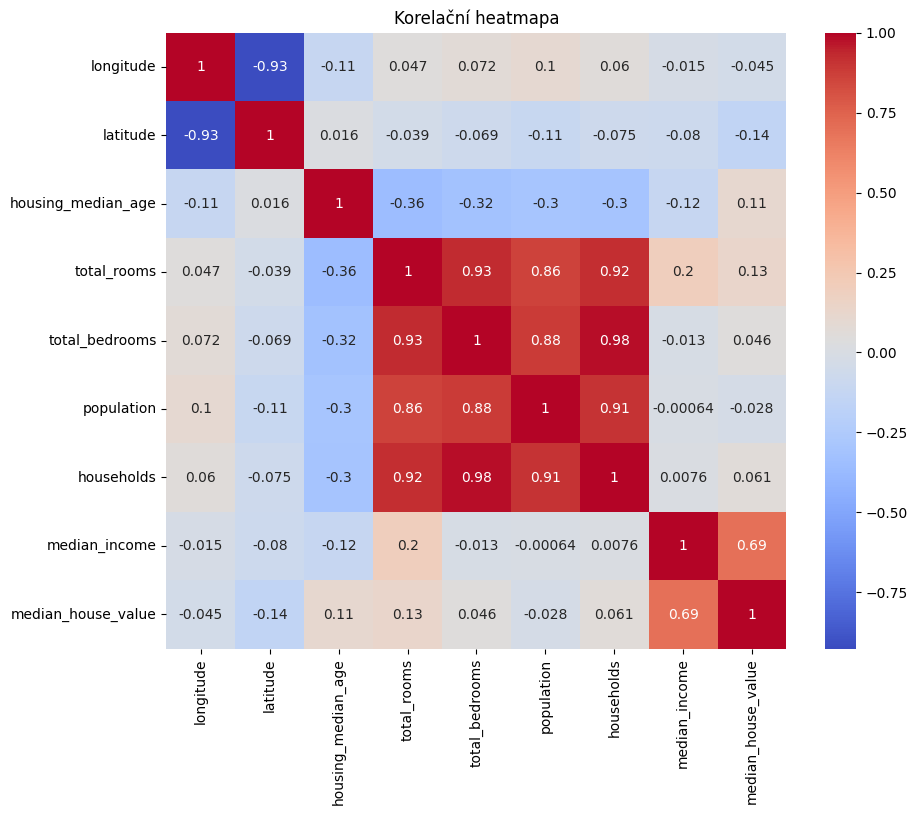

In [ ]:
# Korelační heatmapa - ukazuje nám závislost mezi jednotlivými vlastnostmi
"""
Warning:
Pro generování heatmapy je nutné použít knihovnu seaborn (sns),
která slouží k vykreslování pokročilých grafů a je kompatibilní s knihovnou matplotlib (plt).
"""
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(method="pearson"), annot=True, cmap='coolwarm')
plt.title('Korelační heatmapa')
plt.show()

✍ *Vsuvka:* Zde vidíme že heatmapa je "teplá" 🔥 a proto můžeme říct že mezi jednotlivými vlastnosti je na první pohled korelace - **jsou na sobě závislé**. Tedy, lze třeba říct že když je okvětní lístek dlouhý, bude zároveň úzký, a podobně. To by nám mohlo pomoci říct **které vlastnosti jsou důležitější než ostatní** a které budou pro trénování rozhodující. Jsou to pak důležitá dělící kritéria.  Pozor, stejně důležitá je i záporná korelace - "studená" 🧊!

Jako metodu používáme Pearsonův korelační koeficient, zde je nutné dodat že ten hledá **pouze** lineární korelace! Tzn, pokud tam jsou nějaké složitější korelace, nepř. křivky, tak je pravděpodobně neodhalí...

## 🔷 Lineární regrese
---
V kostce je s nadsázkou schopná linerární regrese předpovídat budoucnost na základě již naučené sekvence dat. Například, dokáže na základě teplot za poslední měsíc předpovědět, jaká teplota bude zítra. 🌤
Samozřejmě, jak už napovídá název, je potřeba aby data byla ideálně lineárního charakteru, protože využívá takzvanou **lineární aproximaci**. Aproximace není nic jiného, než hledání takové funkce, která by co nejvěrněji kopírovala nějaký průběh. V našem případě se jedná o *lineární funkci* (`y = ax + b` kde `a` je sklon, `b` je bias - posun a `x` jsou vstupní data).
Abychom lineární funkci přizpůsobili, potřebujeme ji takzvaně
"*optimalizovat*":
* **Dopočítání z dat** - Spočítáme sklon `a` a následně `b`
* **Gradientní metoda** - U této metody vybereme `a` a `b` náhodně a postupně je podle námi definované chybové funkce optimalizujeme, dokud není chyba co nejmenší
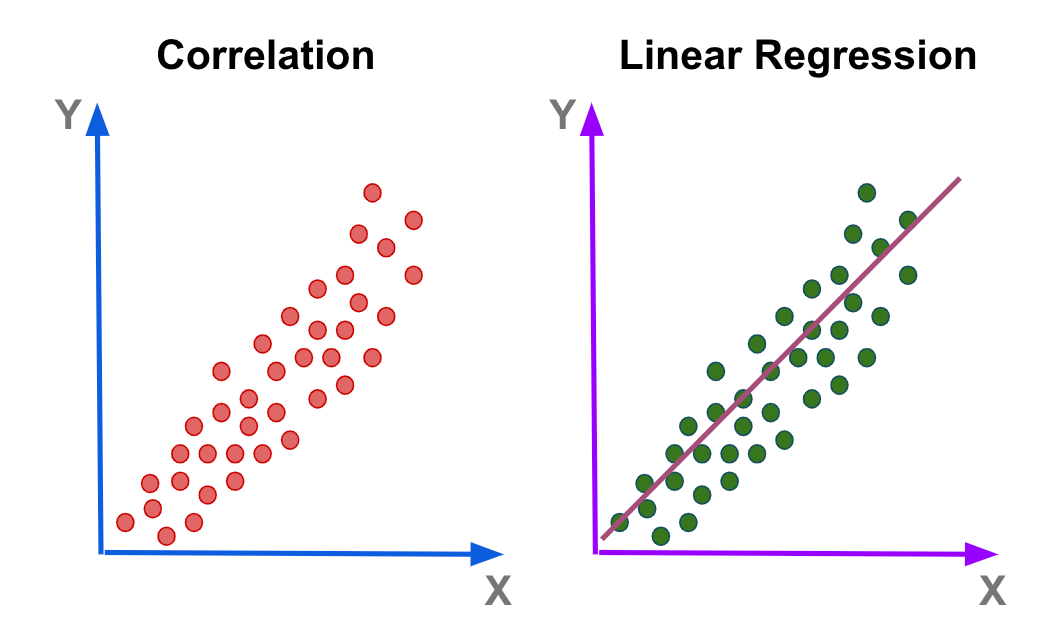

### 🔹 Jak vytvořit svůj LR model?

In [ ]:
# Jak oříznout dataset - zachování pouze zájmové oblasti
df_cutted = df[["longitude", "latitude", "median_income", "median_house_value"]]
df_cutted.head()

In [ ]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='object')

In [ ]:
# Rozdělení na X a Y - vstupy a výstupy

# X - je vstup, to bude poloha, funkcí to_numpy převádíme na Numpy pole
# Prvně otestujeme pouze základní kombinaci, bez dodatečných predikátorů
#X = df[["longitude","latitude"]].to_numpy()
X = df[["longitude","latitude","median_income"]].to_numpy()

# Y - je výstup, to bude cena domu, funkcí to_numpy převádíme na Numpy pole
y = df["median_house_value"].to_numpy()

# tvar x a y
X.shape, y.shape

((17000, 3), (17000,))

In [ ]:
# Kontrola dat
X[:5]

array([[-114.31  ,   34.19  ,    1.4936],
       [-114.47  ,   34.4   ,    1.82  ],
       [-114.56  ,   33.69  ,    1.6509],
       [-114.57  ,   33.64  ,    3.1917],
       [-114.57  ,   33.57  ,    1.925 ]])

In [ ]:
y[:5]

array([66900., 80100., 85700., 73400., 65500.])

✍ *Vsuvka:* Toto dělení dat je velmi běžné, téměř vždy potřebujeme data rozdělit na vstupy - `X` a výstupy - `y`, abychom mohli ML model natrénovat.

###  🔹 Reshape - změna tvaru
Protože model který budeme trénovat vyžaduje aby byla data ve tvaru `[vzorek_1[vlastnosi], ..., vzorek_N[vlastnosi]]` a naše data jsou ve tvaru `[hodnota_1, ..., hodnota_N]`, bude nutné tento tvar změnit. V jazyce datové vědy to znamená, že musíme přidat jednu dimenzi, tzn. z tvaru (17000) udělat tvar (17000, 1). Naštěstí pro nás, je tato operace triviálně jednoduchá - požijeme funkci z knihovny *Numpy* `reshape`.

In [ ]:
# První dimenzi zachováme ve stejném tvaru (-1 značí že má zachovat počet položek) - to jsou naše vzorky, ve druhé bude pouze jedna položka - hodnota (vlastnost)
X = X.reshape(-1,3)
y = y.reshape(-1,1)

# nový tvar x a y
X.shape, y.shape

((17000, 3), (17000, 1))

In [ ]:
# Kontrola dat
X[:5]

array([[-114.31  ,   34.19  ,    1.4936],
       [-114.47  ,   34.4   ,    1.82  ],
       [-114.56  ,   33.69  ,    1.6509],
       [-114.57  ,   33.64  ,    3.1917],
       [-114.57  ,   33.57  ,    1.925 ]])

In [ ]:
y[:5]

array([[66900.],
       [80100.],
       [85700.],
       [73400.],
       [65500.]])

In [ ]:
# Knihovna pro práci s lin. regresí
from sklearn.linear_model import LinearRegression

# Vytvoření modelu LinearRegression - běžný model
reg = LinearRegression()
reg

LinearRegression()

In [ ]:
# Trénování modelu - funce fit
reg.fit(X,y)

LinearRegression()

✍ *Vsuvka:* Jak sami brzo zjistíte, funkce `fit` je běžná pro téměř všechny ML modely. 🔀

In [ ]:
# Otestování skore funkce - výsledek mezi 0 a 1, čím blíže k 1, tím lépe je model schopen aproximovat data a vedl si lépe
reg.score(X,y)

0.5884873383037856

`0.24` je velmi podprůměrné skore, model si aktuálně nevede dobře. Pojďme udělat **predikci**!

In [ ]:
# Na základě X (populace) predikujeme y (počet místností)
y_predict = reg.predict(X)

In [ ]:
# Zde můžeme porovnat predikovaná a skutečná data
y_predict[:5]

array([[-73854.29109862],
       [-64034.35651921],
       [-31205.65099948],
       [ 28524.88073219],
       [-14760.72063125]])

In [ ]:
y[:5]

array([[66900.],
       [80100.],
       [85700.],
       [73400.],
       [65500.]])

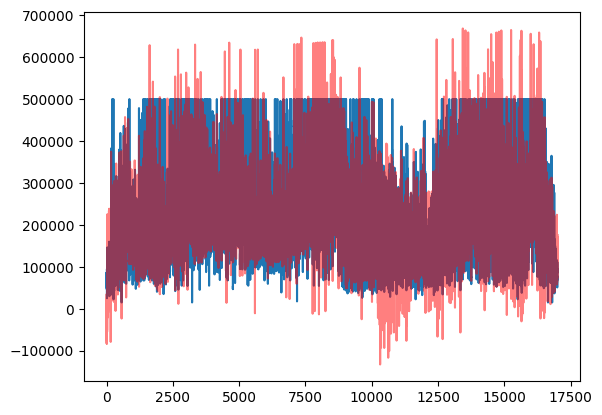

In [ ]:
# Vykreslení grafu a porovnání skutečných a předpovězených hodnot

# Vykreslení skutečných hodnot
# Je nutné používat funkci arenge a lineární generovat časovou osu, také je nutné provést zpětný reshape na 1D pole
plt.plot(np.arange(len(X)), y.reshape(-1))
# Vykreslední predikovaných hodnot
plt.plot(np.arange(len(X)), y_predict.reshape(-1), c="r", alpha=0.5)

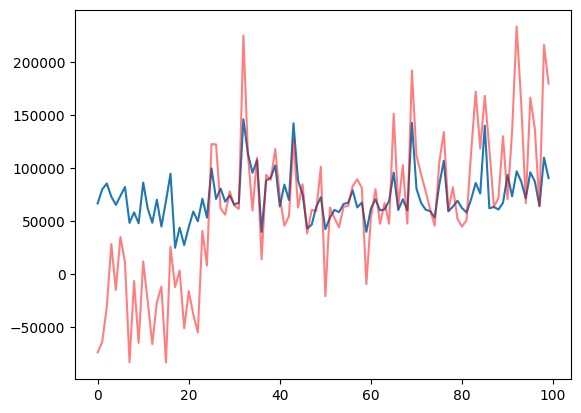

In [ ]:
# Je možné vykreslit jen část dat, pro lepší náhled
n = 100

# Vykreslení skutečných hodnot
plt.plot(np.arange(len(X))[:n], y.reshape(-1)[:n])
# Vykreslední predikovaných hodnot
plt.plot(np.arange(len(X))[:n], y_predict.reshape(-1)[:n], c="r", alpha=0.5)

✍ *Vsuvka:* Tento přístup není úplně validní, model by měl být vždy testován na neznámých datech!

🧠 **Otázka**: Jak by bylo možné zvýšit přesnost modelu? Co bychom pro něj mohli udělat?

### 🔹 Rozdělíme dataset na train/test

In [ ]:
from sklearn.model_selection import train_test_split

# Dělíme data 80:20 ve prospěch trénovacích
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

In [ ]:
# Znovu vytvoříme čistý model
reg = LinearRegression()
reg

LinearRegression()

In [ ]:
# A trénujeme pouze na trenovacích datech
reg.fit(X_train, y_train)

LinearRegression()

In [ ]:
# Ted můžeme testovat na "neznámých" testovacích datech
reg.score(X_test, y_test)

0.6025483697751539

In [ ]:
# Zkusíme predikci
y_predict = reg.predict(X_test)

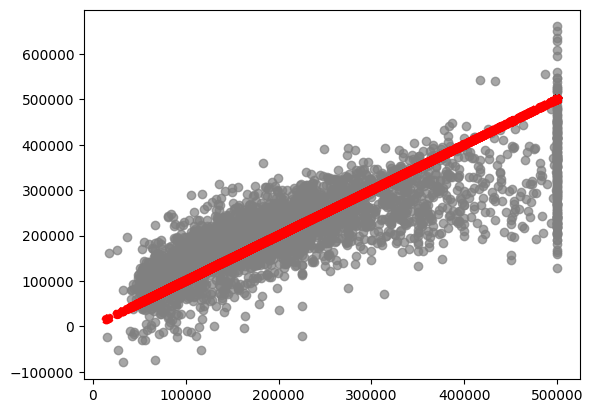

In [ ]:
# Vykreslíme true X predicted křivku
plt.scatter(y_test.reshape(-1), y_predict.reshape(-1), color="gray", alpha=0.7)
plt.scatter(y_test.reshape(-1), y_test.reshape(-1), color="red", linestyle="--")

plt.show()

✍ *Vsuvka:* Zde můžeme vidět skutečný rozptyl mezi predikovanou a skutečnou hodnotou - lineární průběh by odpovídal dokonalému fitu.

## 👉 ÚKOL 1:
Načtěte soubor `monthly.csv` z odkazu [https://pkgstore.datahub.io/core/gold-prices/monthly_csv/data/6b48607cdb24b83067007e7a26b58b57/monthly_csv.csv](https://pkgstore.datahub.io/core/gold-prices/monthly_csv/data/6b48607cdb24b83067007e7a26b58b57/monthly_csv.csv) a uložte ho jako `DataFrame` do proměnné `data`. Vypište prvních 5 záznamů (`head`), a jeho tvar (`shape`). Dále se ujistěte že dataset neobsahuje žádné prázné záznamy (NA) a je načten ve správném formátu dat (data type by měl být `object` a `float`), nakonec vykreslete histogram pro sloupec *Price*.

### Příprava dat
Abychom mohli vytvořit náš model lineární regrese, je první nutné si připravit dataset kterým ho budeme "krmit". 🥙 K tomu využijeme již nám známé knihovny *Numpy* a *Pandas*. Jako vstupní data použijeme index cen zlata, po měsících. 📅


In [ ]:
# řešení úkolu č. 1:
data_url= r"https://pkgstore.datahub.io/core/gold-prices/monthly_csv/data/6b48607cdb24b83067007e7a26b58b57/monthly_csv.csv"
data = # použij pandas

#### Quick EDA (Explorační Analýza)

### Rozdělení na dat na X a Y - vstupy a výstupy

In [ ]:
# Rozdělení na X a Y - vstupy a výstupy

# X - je vstup, jsou to indexy měsíců od 1 do N, kde je počet záznamů, vytváříme jako Numpy pole pomocí funkce arange
X = ???

# Y - je výstup, teda cena zlata v jednotlivých měsících, funkcí to_numpy převádíme na Numpy pole
Y = ???

# tvar x a y
X.shape, y.shape

((834,), (834,))

In [ ]:
# Náhled dat - vyber prvních 5 prvků pomocí slicingu [from:to]
???

array([0, 1, 2, 3, 4])

array([34.73, 34.73, 34.73, 34.73, 34.73])

### Reshape - změna tvaru
Protože model který budeme trénovat vyžaduje aby byla data ve tvaru `[vzorek_1[vlastnosi], ..., vzorek_N[vlastnosi]]` a naše data jsou ve tvaru `[hodnota_1, ..., hodnota_N]`, bude nutné tento tvar změnit. V jazyce datové vědy to znamená, že musíme přidat jednu dimenzi, tzn. z tvaru (834) udělat tvar (834, 1). Naštěstí pro nás, je tato operace triviálně jednoduchá - požijeme funkci z knihovny *Numpy* `reshape`.

In [ ]:
# První dimenzi zachováme ve stejném tvaru (-1 značí že má zachovat počet položek) - to jsou naše vzorky, ve druhé bude pouze jedna položka - hodnota (vlastnost)
X = ???
Y = ???

# nový tvar X a y
X.shape, y.shape

((834, 1), (834, 1))

In [ ]:
# Pojďme se podívat na náhled našich dat v novém tvaru
???

array([[0],
       [1],
       [2],
       [3],
       [4]])

In [ ]:
???

array([[34.73],
       [34.73],
       [34.73],
       [34.73],
       [34.73]])

### Vytvoření modelu
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

In [ ]:
# Vytvoření modelu LinearRegression - běžný model
???

In [ ]:
# Trénování modelu - funce fit
???

LinearRegression()

In [ ]:
# Otestování skore funkce - výsledek mezi 0 a 1, čím blíže k 1, tím lépe je model schopen aproximovat data a vedl si lépe
???

0.6859359867746044

✍ *Vsuvka:* Zde vidíme že si model nevedl zrovna nejlépe 😞, je to tím že tato data nejsou úplně vhodná k predikci pomocí **běžné** lineární regerese, existují ovšem sofistikovanější typy,  které využívají například polynomiální funkce, a jsou na tento typ dat vhodnější.

In [ ]:
# Testování modelu - predikce výstupu na záladě vstupů
???

array([[-221.17834313],
       [-219.69085933],
       [-218.20337553],
       [-216.71589172],
       [-215.22840792]])

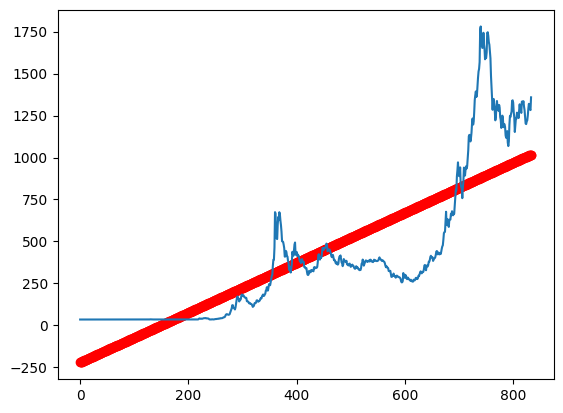

In [ ]:
# Vykreslení grafu a porovnání skutečných a předpovězených hodnot

# Vykreslení skutečných hodnot
???
# Scatter je jednoduchý rychlý graf určený pro rychlé vykreslování dat "X vs Y", c je nastavení barev křivek
# Vykreslední predikovaných hodnot
???

### Předpovídání budoucnosti
Jakmile je model natrénován a validován, je možné jej použít ke skutečné predikci budoucích hodnot. Například k predikování cen zlata v budoucnu. **Let's try it!**

In [ ]:
# Průměrná hodnota zlata pro rok 2022 (měsíc 813-825)
np.average(y[813:825])

1281.8235833333335

In [ ]:
# Očekávaná hodnota zlata pro rok 2025 (měsíce 838-849)
X_future = np.arange(838, 850).reshape(-1,1)
X_future

array([[838],
       [839],
       [840],
       [841],
       [842],
       [843],
       [844],
       [845],
       [846],
       [847],
       [848],
       [849]])

In [ ]:
# Necháme model prediktovat hodnoty cen zlata pro měsíce 838-849
???
# Predict
???
# Average
avarage = ???
avarage

1033.514244403195

### 👉 ÚKOL 2:
Zkuste porovnat cenu zlata pro rok 2022 (měsíc 813-825) dle skutečných hodnot a dle predikovaných hodnot. Výsledek interpretujte do grafu - vykreslete skutečné hodnoty a predikci. Zamyslete se nad správností modelu. 🤔

In [ ]:
# řešení úkolu č. 2:

# Definuj X_2022
???
# definuj y_2022
???

array([[813],
       [814],
       [815],
       [816],
       [817],
       [818],
       [819],
       [820],
       [821],
       [822],
       [823],
       [824]])

In [ ]:
# Udělej fit
???

In [ ]:
# Udělej predikci y_2022_predicted
???

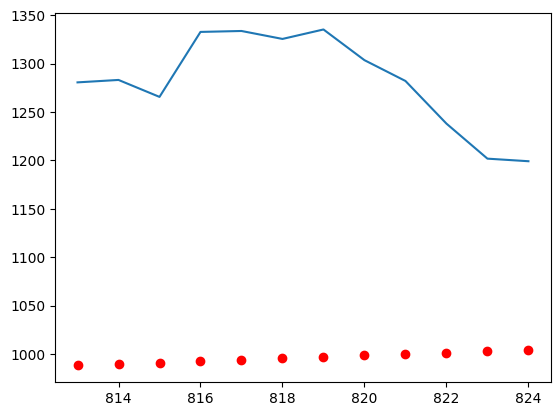

In [ ]:
# Vykreslení grafu plot pro y_2022 a scatter pro y_2022_predicted
???

### 👉 ÚKOL 3:
Zkuste natrénovat složitější regresní model níže, využívající spojení polynomiálního preprocesingu dat a  lineární regrese = polynomiální regrese. 🔥 Proveďte opět predikci cen zlata a porovnejte s obyčejným lin. regresním modelem výše ☝

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Vytvoříme si model s polynomiální regresí stupně 2
degree = 10
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())

✍ *Vsuvka:* Postup je stejný jako byl u klasického jednoduchého modelu výše.

In [ ]:
#řešení úkolu č. 3:
???

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=10)),
                ('linearregression', LinearRegression())])

In [ ]:
# Skore
???

0.9377998220867756

In [ ]:
# Predikt
y_predicted_poly = ???

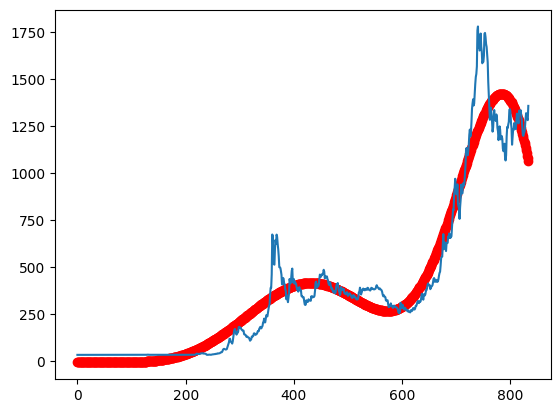

In [ ]:
# Predict
plt.plot(X, y)
plt.scatter(X, y_predicted_poly, c="r")